# Actividad 1 — Integración SQL–Python y conjunto de trabajo

**Variante 5: Rendimiento comercial por tienda y empleado.**

**Pregunta de negocio:** ¿Cómo se reparte el negocio entre las tiendas y entre quienes atienden? ¿Las diferencias son de volumen o de comportamiento de compra?

Este notebook distingue el **conjunto de trabajo optimizado** (puntos 1.1 y 1.2) de la **comparación sobre pagos individuales** (punto 1.4).


## Preparación — Bibliotecas y conexión a SQL Server


In [2]:
# ACTIVIDAD 1 ANÁLISIS COMERCIAL DE SAKILA
#  importar las bibliotecas necesarias

import pandas as pd
import mssql_python
import os
from dotenv import load_dotenv

print("Pandas:", pd.__version__)
print("Bibliotecas importadas correctamente")

Pandas: 3.0.6
Bibliotecas importadas correctamente


In [3]:
# ACTIVIDAD 1 CONEXIÓN A SQL SERVER
# Objetivo: conectarnos a Sakila_Espanol utilizando
# las credenciales guardadas en el archivo .env.

# Cargamos las variables de entorno
load_dotenv()

servidor = os.getenv("DB_SERVER")
puerto = os.getenv("DB_PORT")
base_datos = os.getenv("DB_NAME")
usuario = os.getenv("DB_USER")
contrasena = os.getenv("DB_PASSWORD")

# Establecemos la conexión con SQL Server
conexion = mssql_python.connect(
    f"SERVER={servidor},{puerto};"
    f"DATABASE={base_datos};"
    f"UID={usuario};"
    f"PWD={contrasena};"
    "Encrypt=yes;"
    "TrustServerCertificate=yes;"
)

# Verificamos a qué base de datos estamos conectados
cursor = conexion.cursor()
cursor.execute("SELECT DB_NAME()")

resultado = cursor.fetchone()

print("¡Conexión exitosa!")
print("Base de datos:", resultado[0])

cursor.close()

# Mantenemos la conexión abierta para las siguientes consultas.

¡Conexión exitosa!
Base de datos: Sakila_Espanol


## Punto 1.1 — Consulta T-SQL y conjunto de trabajo optimizado

SQL Server realiza las uniones, las agregaciones y los cálculos de participación mediante funciones de ventana. La consulta devuelve una fila por empleado.


In [4]:
# ACTIVIDAD 1  PUNTO 1.1
# Conjunto de trabajo optimizado en SQL Server.
# Objetivo:
# Calcular el rendimiento comercial por tienda y empleado
# directamente en SQL Server, evitando trasladar todos los pagos.

consulta_rendimiento = """
WITH rendimiento AS (
    SELECT
        e.tienda_id,
        e.empleado_id,
        e.nombre,
        e.apellido,
        COUNT(p.pago_id) AS cantidad_pagos,
        SUM(p.monto) AS ingresos_totales,
        AVG(p.monto) AS ticket_promedio
    FROM empleado AS e
    LEFT JOIN pago AS p
        ON e.empleado_id = p.empleado_id
    GROUP BY
        e.tienda_id,
        e.empleado_id,
        e.nombre,
        e.apellido
)
SELECT
    tienda_id,
    empleado_id,
    nombre,
    apellido,
    cantidad_pagos,
    ingresos_totales,
    ticket_promedio,

    -- Ingresos totales de la tienda.
    SUM(ingresos_totales) OVER (
        PARTITION BY tienda_id
    ) AS total_tienda,

    -- Porcentaje del empleado dentro de su tienda.
    100.0 * ingresos_totales /
    NULLIF(
        SUM(ingresos_totales) OVER (
            PARTITION BY tienda_id
        ), 0
    ) AS participacion_empleado,

    -- Porcentaje de la tienda sobre el negocio completo.
    100.0 * SUM(ingresos_totales) OVER (
        PARTITION BY tienda_id
    ) /
    NULLIF(
        SUM(ingresos_totales) OVER (), 0
    ) AS participacion_negocio

FROM rendimiento
ORDER BY tienda_id, empleado_id
"""



## Punto 1.2 — Carga del resultado con `pandas.read_sql()`

Ejecutamos la consulta del punto 1.1 y cargamos el conjunto de trabajo optimizado en pandas. Esta consulta no utiliza valores variables, por eso no requiere `params`. Si se agregan filtros variables, deben enviarse mediante `params`, nunca con concatenación ni f-strings.


In [5]:
# Ejecutamos la consulta en SQL Server.
# pandas recibe únicamente los resultados agrupados.
df_rendimiento_optimizado = pd.read_sql(
    consulta_rendimiento,
    conexion
)

# Mostramos los resultados.
display(df_rendimiento_optimizado)

# Verificamos cuántas filas recibimos.
print("Cantidad de filas:", len(df_rendimiento_optimizado))

/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_34723/2398989944.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_rendimiento_optimizado = pd.read_sql(


,tienda_id,empleado_id,nombre,apellido,cantidad_pagos,ingresos_totales,ticket_promedio,total_tienda,participacion_empleado,participacion_negocio
0,1,1,Mike,Hillyer,8054,33482.50,4.157251,33482.50,100.0,49.672465
1,2,2,Jon,Stephens,7990,33924.06,4.245814,33924.06,100.0,50.327534


Cantidad de filas: 2


### Punto 1.3 — Justificación del reparto de trabajo entre SQL Server y pandas

**SQL Server:** se encarga de realizar las operaciones más pesadas del procesamiento de datos. Para nuestro análisis de rendimiento comercial, une las tablas `empleado` y `pago`, cuenta las operaciones, suma los ingresos, calcula el ticket promedio y obtiene las participaciones porcentuales por empleado y tienda mediante funciones de ventana como `SUM(...) OVER (...)`.

De esta manera, las agregaciones se realizan directamente en el motor de base de datos, evitando transferir los 16.044 pagos individuales cuando solamente necesitamos los resultados agrupados.

**pandas:** recibe mediante `pd.read_sql()` el conjunto de trabajo procesado por SQL Server y lo almacena en un DataFrame para facilitar su inspección, análisis y visualización.

Además, en el punto 1.4 utilizamos los datos crudos de los pagos para calcular las mismas métricas con pandas mediante `groupby()` y `transform()`, y comparar los resultados con los obtenidos en SQL Server.

**Justificación de la división del trabajo:**

Elegimos realizar las uniones y agregaciones principales en SQL Server porque está diseñado para procesar grandes volúmenes de datos de manera eficiente. Pandas se utiliza para analizar, validar y visualizar los resultados.

Esta división reduce la cantidad de información transferida desde la base de datos hacia Python y permite comparar ambos enfoques para verificar la consistencia de los cálculos.

## Punto 1.4 — Comparación de SQL Server y pandas con datos crudos

Para este punto se cargan los pagos individuales necesarios para calcular en pandas las mismas métricas que se calculan en T-SQL. 


In [6]:
# ACTIVIDAD 1 CARGA DE DATOS CON PANDAS
# Objetivo: obtener los pagos y la tienda de cada empleado.

consulta_pagos = """
SELECT
    p.pago_id,
    p.empleado_id,
    p.cliente_id,
    p.monto,
    e.tienda_id
FROM pago AS p
LEFT JOIN empleado AS e
    ON p.empleado_id = e.empleado_id
"""

# Ejecutamos la consulta SQL
cursor = conexion.cursor()
cursor.execute(consulta_pagos)

# Recuperamos las columnas y los registros
columnas = [columna[0] for columna in cursor.description]
filas = cursor.fetchall()

# Convertimos los resultados en un DataFrame
df_pagos = pd.DataFrame.from_records(filas, columns=columnas)

cursor.close()

print("Cantidad de pagos:", len(df_pagos))
display(df_pagos.head())

Cantidad de pagos: 16044


,pago_id,empleado_id,cliente_id,monto,tienda_id
0,1,1,1,2.99,1
1,2,1,1,0.99,1
2,3,1,1,5.99,1
3,4,2,1,0.99,2
4,5,2,1,9.99,2


In [7]:
# ACTIVIDAD 1  LECTURA DE DATOS CON PANDAS
# Objetivo: cargar los pagos utilizando pd.read_sql().

df_pagos_sql = pd.read_sql(
    consulta_pagos,
    conexion
)

# Verificamos la cantidad de registros obtenidos
print("Cantidad de pagos:", len(df_pagos_sql))

# Mostramos las primeras cinco filas
display(df_pagos_sql.head())

Cantidad de pagos: 16044


/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_34723/4201456945.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pagos_sql = pd.read_sql(


,pago_id,empleado_id,cliente_id,monto,tienda_id
0,1,1,1,2.99,1
1,2,1,1,0.99,1
2,3,1,1,5.99,1
3,4,2,1,0.99,2
4,5,2,1,9.99,2


In [8]:
# ACTIVIDAD 1 RENDIMIENTO POR EMPLEADO
# Objetivo: calcular pagos, ingresos y ticket promedio.

rendimiento_empleados = (
    df_pagos_sql
    .groupby(["tienda_id", "empleado_id"])
    .agg(
        cantidad_pagos=("pago_id", "count"),
        ingresos_totales=("monto", "sum"),
        ticket_promedio=("monto", "mean")
    )
    .reset_index()
)

display(rendimiento_empleados)

,tienda_id,empleado_id,cantidad_pagos,ingresos_totales,ticket_promedio
0,1,1,8054,33482.50,4.157251
1,2,2,7990,33924.06,4.245815


In [9]:
# ACTIVIDAD 1 PARTICIPACIÓN POR EMPLEADO
# Objetivo: calcular qué porcentaje de los ingresos
# de cada tienda corresponde a cada empleado.

rendimiento_empleados["total_tienda"] = (
    rendimiento_empleados
    .groupby("tienda_id")["ingresos_totales"]
    .transform("sum")
)

rendimiento_empleados["participacion_empleado"] = (
    rendimiento_empleados["ingresos_totales"]
    / rendimiento_empleados["total_tienda"]
    * 100
)

display(rendimiento_empleados)

,tienda_id,empleado_id,cantidad_pagos,ingresos_totales,ticket_promedio,total_tienda,participacion_empleado
0,1,1,8054,33482.50,4.157251,33482.50,100.0
1,2,2,7990,33924.06,4.245815,33924.06,100.0


In [10]:
# ACTIVIDAD 1 PARTICIPACIÓN DE CADA TIENDA
# Objetivo: calcular qué porcentaje del ingreso total
# del negocio corresponde a cada tienda.

# Sumamos los ingresos de todas las tiendas.
ingresos_negocio = rendimiento_empleados["ingresos_totales"].sum()

# Calculamos el porcentaje que aporta cada tienda.
rendimiento_empleados["participacion_negocio"] = (
    rendimiento_empleados["total_tienda"]
    / ingresos_negocio
    * 100
)

print("Ingresos totales del negocio:", round(ingresos_negocio, 2))

display(
    rendimiento_empleados[
        ["tienda_id", "total_tienda", "participacion_negocio"]
    ]
)

Ingresos totales del negocio: 67406.56


,tienda_id,total_tienda,participacion_negocio
0,1,33482.50,49.672465
1,2,33924.06,50.327535


In [11]:
# ACTIVIDAD 1 VALIDACIÓN SQL VS PANDAS
# Objetivo: comprobar que ambos métodos
# calculan los mismos ingresos por empleado.

consulta_validacion = """
SELECT
    e.tienda_id,
    p.empleado_id,
    COUNT(*) AS cantidad_pagos,
    SUM(p.monto) AS ingresos_sql
FROM pago AS p
INNER JOIN empleado AS e
    ON p.empleado_id = e.empleado_id
GROUP BY e.tienda_id, p.empleado_id
ORDER BY e.tienda_id, p.empleado_id
"""

# Ejecutamos el cálculo en SQL Server.
df_sql = pd.read_sql(consulta_validacion, conexion)

# Comparamos con los resultados calculados en pandas.
comparacion = df_sql.merge(
    rendimiento_empleados[
        ["tienda_id", "empleado_id", "cantidad_pagos", "ingresos_totales"]
    ],
    on=["tienda_id", "empleado_id"],
    suffixes=("_sql", "_pandas")
)

# Calculamos la diferencia entre ambos resultados.
comparacion["diferencia_ingresos"] = (
    comparacion["ingresos_sql"]
    - comparacion["ingresos_totales"]
).round(2)

display(comparacion)

/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_34723/974169900.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sql = pd.read_sql(consulta_validacion, conexion)


,tienda_id,empleado_id,cantidad_pagos_sql,ingresos_sql,cantidad_pagos_pandas,ingresos_totales,diferencia_ingresos
0,1,1,8054,33482.50,8054,33482.50,0.0
1,2,2,7990,33924.06,7990,33924.06,-0.0


In [12]:
# ACTIVIDAD 1 COMPARACIÓN DE RENDIMIENTO
# Objetivo: comparar el tiempo de cálculo
# de ingresos por empleado en SQL y pandas.

from time import perf_counter

# Medimos cuánto tarda SQL Server en calcular los resultados.
inicio_sql = perf_counter()

resultado_sql = pd.read_sql(consulta_validacion, conexion)

fin_sql = perf_counter()

# Medimos cuánto tarda pandas en calcular los mismos resultados.
inicio_pandas = perf_counter()

resultado_pandas = (
    df_pagos_sql
    .groupby(["tienda_id", "empleado_id"])
    .agg(
        cantidad_pagos=("pago_id", "count"),
        ingresos_totales=("monto", "sum")
    )
    .reset_index()
)

fin_pandas = perf_counter()

# Calculamos los tiempos transcurridos.
tiempo_sql = fin_sql - inicio_sql
tiempo_pandas = fin_pandas - inicio_pandas

print(f"Tiempo SQL Server: {tiempo_sql:.6f} segundos")
print(f"Tiempo pandas: {tiempo_pandas:.6f} segundos")

Tiempo SQL Server: 0.020786 segundos
Tiempo pandas: 0.001735 segundos


/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_34723/2091895298.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  resultado_sql = pd.read_sql(consulta_validacion, conexion)


 Comparación de resultados y tiempos de ejecución

Se analizaron 16.044 pagos de la base de datos Sakila_Espanol.

Los ingresos y la cantidad de operaciones calculados mediante SQL Server coincidieron con los obtenidos utilizando pandas.

Resultados comerciales:
- Tienda 1: 8.054 pagos, ingresos de 33.482,50 y ticket promedio de 4,16.
- Tienda 2: 7.990 pagos, ingresos de 33.924,06 y ticket promedio de 4,25.
- Ingresos totales: 67.406,56.

La tienda 2 generó más ingresos a pesar de registrar menos operaciones. Esto indica que la diferencia está relacionada con el ticket promedio y no solamente con el volumen de pagos.

Comparación de rendimiento:
- Tiempo SQL Server: 0.020786 segundos
- Tiempo pandas: 0.001735 segundos

En esta ejecución, pandas presentó un menor tiempo de procesamiento. Sin embargo, la comparación tiene limitaciones: la medición de SQL incluye la consulta y transferencia de resultados, mientras que pandas utiliza datos previamente cargados en memoria.

Por lo tanto, estos tiempos no permiten determinar cuál tecnología es más eficiente en términos generales.

## Controles de calidad de datos


In [13]:
# ACTIVIDAD 1 CONTROL DE CALIDAD DE DATOS
# Objetivo: detectar pagos sin un empleado válido.

# Seleccionamos los pagos que no tienen tienda asociada.
pagos_sin_empleado = df_pagos_sql[
    df_pagos_sql["tienda_id"].isna()
]

print("Cantidad total de pagos:", len(df_pagos_sql))
print("Pagos sin empleado válido:", len(pagos_sin_empleado))

display(pagos_sin_empleado.head())

Cantidad total de pagos: 16044
Pagos sin empleado válido: 0


,pago_id,empleado_id,cliente_id,monto,tienda_id


In [14]:
# ACTIVIDAD 1 CONTROL DE CALIDAD
# Objetivo: detectar empleados sin pagos registrados.

consulta_empleados_sin_pagos = """
SELECT
    e.empleado_id,
    e.nombre,
    e.apellido,
    e.tienda_id,
    COUNT(p.pago_id) AS cantidad_pagos
FROM empleado AS e
LEFT JOIN pago AS p
    ON e.empleado_id = p.empleado_id
GROUP BY
    e.empleado_id,
    e.nombre,
    e.apellido,
    e.tienda_id
HAVING COUNT(p.pago_id) = 0
"""

df_empleados_sin_pagos = pd.read_sql(
    consulta_empleados_sin_pagos,
    conexion
)

print("Empleados sin pagos:", len(df_empleados_sin_pagos))

display(df_empleados_sin_pagos)

Empleados sin pagos: 0


/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_34723/1260564209.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_empleados_sin_pagos = pd.read_sql(


,empleado_id,nombre,apellido,tienda_id,cantidad_pagos


In [15]:
# ACTIVIDAD 1 CONTROL DE CALIDAD
# Objetivo: identificar clientes cuyos pagos
# fueron procesados en más de una tienda.

consulta_clientes_ambas_tiendas = """
SELECT
    p.cliente_id,
    COUNT(DISTINCT e.tienda_id) AS cantidad_tiendas
FROM pago AS p
INNER JOIN empleado AS e
    ON p.empleado_id = e.empleado_id
GROUP BY p.cliente_id
HAVING COUNT(DISTINCT e.tienda_id) > 1
"""

df_clientes_ambas_tiendas = pd.read_sql(
    consulta_clientes_ambas_tiendas,
    conexion
)

print(
    "Clientes con pagos procesados en ambas tiendas:",
    len(df_clientes_ambas_tiendas)
)

display(df_clientes_ambas_tiendas.head())

Clientes con pagos procesados en ambas tiendas: 599


/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_34723/3723629162.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_clientes_ambas_tiendas = pd.read_sql(


,cliente_id,cantidad_tiendas
0,1,2
1,2,2
2,3,2
3,4,2
4,5,2


 Controles de calidad de datos

Se realizaron tres controles sobre la base de datos Sakila_Espanol para verificar la integridad de los registros utilizados en el análisis comercial.

1. Pagos sin empleado válido

Se analizaron 16.044 pagos y no se encontraron registros sin un empleado asociado.

Resultado: 0 pagos sin empleado válido.

2. Empleados sin pagos

Se verificó si existían empleados registrados que no hubieran procesado ninguna operación.

Resultado: 0 empleados sin pagos.

3. Clientes con pagos procesados en ambas tiendas

Se identificaron los clientes cuyos pagos fueron procesados por empleados pertenecientes a más de una tienda.

Resultado: 599 clientes.

Este resultado no implica necesariamente que los clientes hayan visitado físicamente ambas tiendas, sino que sus pagos fueron procesados por empleados asociados a las dos tiendas.

Conclusión

Los controles no detectaron pagos sin empleado válido ni empleados sin operaciones. Esto favorece la consistencia del análisis de ingresos por empleado y por tienda.

La presencia de clientes con pagos procesados en ambas tiendas debe considerarse al interpretar el comportamiento comercial, ya que la tienda del empleado que procesa el pago no necesariamente representa la tienda de origen del cliente.

## Visualizaciones y análisis comercial


In [16]:
# ACTIVIDAD 1 PREPARACIÓN DE VISUALIZACIONES
# Objetivo: comprobar que matplotlib está disponible.

import matplotlib.pyplot as plt

print("Matplotlib está disponible para crear gráficos")

Matplotlib está disponible para crear gráficos


### Gráfico 1 — Participación del empleado en su tienda (100 % apilado)


In [17]:
# ACTIVIDAD 1 VERIFICACIÓN DE EMPLEADOS POR TIENDA
# Objetivo: comprobar cuántos empleados
# están registrados en cada tienda.

consulta_empleados_tienda = """
SELECT
    tienda_id,
    COUNT(*) AS cantidad_empleados
FROM empleado
GROUP BY tienda_id
ORDER BY tienda_id
"""

df_empleados_tienda = pd.read_sql(
    consulta_empleados_tienda,
    conexion
)

display(df_empleados_tienda)

/var/folders/cn/rlqrdxlx7_s99d2kjb3ztf1c0000gn/T/ipykernel_34723/3156482476.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_empleados_tienda = pd.read_sql(


,tienda_id,cantidad_empleados
0,1,1
1,2,1


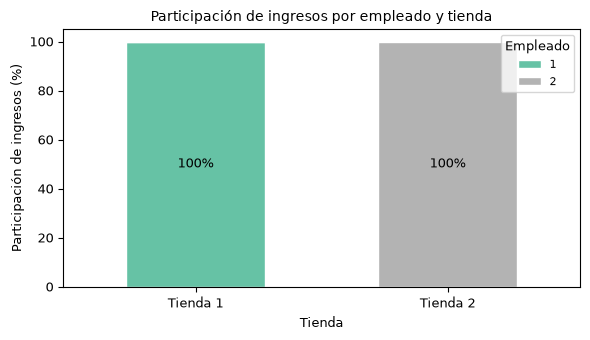

In [18]:
# ACTIVIDAD 1 GRÁFICO DE BARRAS APILADAS AL 100 %
# Objetivo: visualizar la participación de cada empleado
# en los ingresos de su tienda.

# Organizamos los porcentajes por tienda y empleado.
datos_grafico = rendimiento_empleados.pivot(
    index="tienda_id",
    columns="empleado_id",
    values="participacion_empleado"
).fillna(0)

# Creamos el gráfico con un tamaño más pequeño.
ax = datos_grafico.plot(
    kind="bar",
    stacked=True,
    figsize=(6, 3.5),
    colormap="Set2",
    edgecolor="white",
    width=0.55
)

# Agregamos el título y los nombres de los ejes.
ax.set_title(
    "Participación de ingresos por empleado y tienda",
    fontsize=10
)

ax.set_xlabel("Tienda", fontsize=9)
ax.set_ylabel("Participación de ingresos (%)", fontsize=9)

# Establecemos la escala de porcentajes.
ax.set_ylim(0, 105)

# Ajustamos el tamaño de los números.
ax.tick_params(axis="both", labelsize=9)

# Dejamos los nombres de las tiendas horizontales.
ax.set_xticklabels(
    [f"Tienda {tienda}" for tienda in datos_grafico.index],
    rotation=0
)

# Identificamos a los empleados.
ax.legend(
    title="Empleado",
    fontsize=8,
    title_fontsize=9,
    loc="upper right"
)

# Mostramos los porcentajes dentro de las barras.
for contenedor in ax.containers:
    etiquetas = [
        f"{barra.get_height():.0f}%"
        if barra.get_height() > 0 else ""
        for barra in contenedor
    ]

    ax.bar_label(
        contenedor,
        labels=etiquetas,
        label_type="center",
        fontsize=9
    )

# Ajustamos los espacios y mostramos el gráfico.
plt.tight_layout()
plt.show()

Interpretación del gráfico de participación por empleado

El gráfico de barras apiladas al 100 % representa la contribución de cada empleado a los ingresos procesados en su tienda.

Se verificó mediante una consulta SQL a la tabla `empleado` que existen únicamente dos empleados registrados: uno en la tienda 1 y otro en la tienda 2.

Por este motivo, cada empleado representa el 100 % de los ingresos de su respectiva tienda.

Limitación del análisis: aunque el gráfico cumple con la visualización solicitada, no permite comparar la distribución de ingresos entre varios empleados de una misma tienda, ya que la base de datos contiene solamente uno por tienda.

Para complementar esta información, resulta útil comparar los ingresos totales y el ticket promedio de ambas tiendas.

### Gráfico 2 — Ingresos totales por tienda


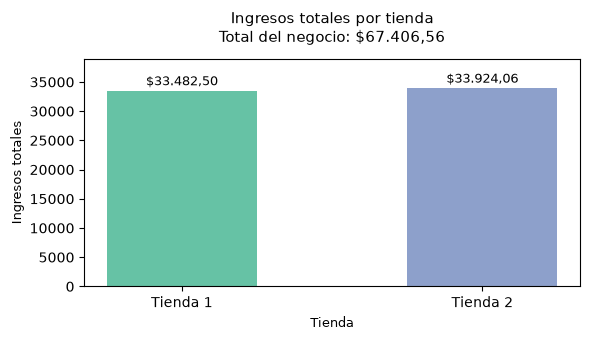

In [19]:
# ACTIVIDAD 1 COMPARACIÓN DE INGRESOS POR TIENDA
# Objetivo: comparar los ingresos de ambas tiendas
# y mostrar el total general del negocio.

# Agrupamos los ingresos por tienda.
ingresos_tiendas = (
    rendimiento_empleados
    .groupby("tienda_id")["ingresos_totales"]
    .sum()
)

# Calculamos los ingresos totales del negocio.
total_negocio = ingresos_tiendas.sum()

# Función para mostrar los importes en formato argentino.
def formato_pesos(valor):
    numero = f"{valor:,.2f}"
    numero = numero.replace(",", "X").replace(".", ",").replace("X", ".")
    return f"${numero}"

# Creamos el gráfico.
fig, ax = plt.subplots(figsize=(6, 3.5))

barras = ax.bar(
    [f"Tienda {tienda}" for tienda in ingresos_tiendas.index],
    ingresos_tiendas.values,
    color=["#66C2A5", "#8DA0CB"],
    width=0.5
)

# Agregamos el título y el total del negocio.
ax.set_title(
    f"Ingresos totales por tienda\n"
    f"Total del negocio: {formato_pesos(total_negocio)}",
    fontsize=11,
    pad=12
)

# Agregamos los nombres de los ejes.
ax.set_xlabel("Tienda", fontsize=9)
ax.set_ylabel("Ingresos totales", fontsize=9)

# Mostramos los ingresos encima de cada barra.
for barra in barras:
    altura = barra.get_height()

    ax.annotate(
        formato_pesos(altura),
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

# Dejamos espacio para mostrar los importes.
ax.set_ylim(0, ingresos_tiendas.max() * 1.15)

# Ajustamos los espacios.
plt.tight_layout()

# Mostramos el gráfico.
plt.show()

Interpretación del gráfico de ingresos totales por tienda

El gráfico compara los ingresos generados por las dos tiendas de la base de datos Sakila_Espanol.

Resultados obtenidos:

- Tienda 1: 8.054 pagos e ingresos de $33.482,50.
- Tienda 2: 7.990 pagos e ingresos de $33.924,06.
- Ingresos totales del negocio: $67.406,56.

La tienda 2 generó $441,56 más que la tienda 1, a pesar de haber procesado 64 pagos menos.

Esta diferencia se relaciona con el ticket promedio de cada tienda:

- Tienda 1: $4,16 por pago.
- Tienda 2: $4,25 por pago.

Conclusión del análisis

Los resultados muestran que una mayor cantidad de operaciones no implica necesariamente mayores ingresos. La tienda 1 procesó más pagos, pero la tienda 2 obtuvo una facturación ligeramente superior debido a su mayor ticket promedio.

Por lo tanto, para evaluar el rendimiento comercial es necesario considerar tanto el volumen de operaciones como el importe promedio de cada pago.

Este gráfico complementa el gráfico de barras apiladas al 100 %, ya que permite comparar los ingresos absolutos de ambas tiendas.

## Conclusión general

Las tiendas presentan ingresos cercanos, aunque la tienda 2 recauda ligeramente más con menos pagos. La comparación de volumen y ticket promedio permite explicar esa diferencia. La contribución del empleado dentro de cada tienda es del 100 % porque en los datos existe un empleado por tienda.

**Alcance:** la tienda se atribuye según el empleado que procesó el pago; esto no demuestra en qué local estuvo físicamente el cliente.
